# Module 05: ODD+LLM Protocol, Reproducibility & Audit Trails

Welcome to the capstone module of the **HydroReOpLLM** tutorial curriculum. Scientific agent-based modeling requires more than high benchmark scores: reviewers and peers must be able to inspect every cognitive, prompt, inference, and physical-validation assumption and reproduce exact outputs without live LLM API calls.

This module demonstrates **HydroReOpLLM**'s built-in **ODD+LLM** (`odd-llm-reproducibility.v1`) protocol pipeline end to end — **Execute & Verify → Inspect & Export → Audit & Plot → Offline Replay**:

| Stage | What You Do | Key HydroReOpLLM API / File |
| --- | --- | --- |
| **1. Execute & Verify** | Run full-year 2021 F.E. Walter `rule_based.yaml` inside `TemporaryDirectory()` and audit every stream & SHA-256 hash | `run_settings(..., allow_network=False)` → `verify_run(..., require_offline=True)` |
| **2. Inspect & Export** | Load `odd_llm_manifest.json` directly from the run directory, inspect all 5 ODD+LLM blocks (`A`–`E`), and export a Markdown report | `odd_llm_manifest.json`, `export_odd_report(..., markdown_out=...)` |
| **3. Audit & Plot** | Visualize per-step mass-balance residuals alongside physical clipping, spill, and audit status counts | `reservoir_trajectory.csv`, `audit.jsonl` |
| **4. Offline Replay** | Reproduce exact `archived_releases.csv` SHA-256 hashes and 2025 Xindian River cascade metrics with `network_calls = 0` | `examples/multi_reservoir/study/replay.py` |

> **Offline & Clean Workspace Guarantee:** Every run and replay in this notebook writes strictly inside `tempfile.TemporaryDirectory()` with `0` network calls, leaving the repository working tree completely clean.


## 0. Locate the Repository & Configure Plotting


In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "examples" / "fe_walter" / "rule_based.yaml"
        ).is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the HydroReOpLLM repository root. "
        "Launch JupyterLab from the repository root, tutorials/, or a module folder."
    )

REPO_ROOT = find_repo_root(Path.cwd().resolve())
SRC_DIR = REPO_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "grid.linestyle": "--",
    "font.size": 9.5,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
    "legend.frameon": True,
    "legend.framealpha": 0.92,
    "legend.edgecolor": "#d8d8d8",
})

print("Repository located cleanly (relative check: pyproject.toml + examples/fe_walter/rule_based.yaml found).")


Repository located cleanly (relative check: pyproject.toml + examples/fe_walter/rule_based.yaml found).


## 1. Execute & Verify — Run F.E. Walter `rule_based.yaml` Offline (`verify_run`)

Every completed HydroReOpLLM run automatically persists an **ODD+LLM manifest** (`odd_llm_manifest.json`) alongside its trace streams (`decisions.jsonl`, `physics.jsonl`, `audit.jsonl`) and tabular outputs (`reservoir_trajectory.csv`, `network_flows.csv`, `network_balance.csv`), and pins its SHA-256 hash inside `summary.json["summary"]["additional_output_files"]`.

Here we run a full-year **2021** (`365`-day) F.E. Walter `rule_based.yaml` simulation inside `tempfile.TemporaryDirectory()`, verify it offline with `verify_run(..., require_offline=True)`, load `odd_llm_manifest.json` directly from the run directory, and export a publication-ready Markdown report via `export_odd_report(..., markdown_out=...)`.


In [2]:
import hashlib
import json
import tempfile
import yaml
import pandas as pd

from llm_reservoir_agent.odd_llm import ODD_LLM_SCHEMA_VERSION, export_odd_report
from llm_reservoir_agent.verification import verify_run
from llm_reservoir_agent.workflow import load_settings, run_settings

fe_dir = REPO_ROOT / "examples" / "fe_walter"
rule_yaml = yaml.safe_load((fe_dir / "rule_based.yaml").read_text(encoding="utf-8"))

with tempfile.TemporaryDirectory(prefix="odd-llm-m05-") as tmp:
    tmp_path = Path(tmp)
    out_dir = tmp_path / "fe-walter-rule-2021"

    cfg = dict(rule_yaml)
    cfg["case"] = str((fe_dir / "rule_case.json").resolve())
    cfg["run_id"] = "fe-walter-rule-2021-odd-audit"
    cfg["output"] = str(out_dir)
    cfg["start_date"] = "2021-01-01"
    cfg["end_date"] = "2021-12-31"
    cfg["extensions"] = {"hanasaki": str((fe_dir / "study" / "rule" / "__init__.py").resolve())}
    cfg["agents"] = {
        "walter_operator": {
            **rule_yaml["agents"]["walter_operator"],
            "rule_parameters": {
                **rule_yaml["agents"]["walter_operator"]["rule_parameters"],
                "inflow_statistics_file": str((fe_dir / "rule_statistics.json").resolve()),
            },
        }
    }
    cfg_path = tmp_path / "rule_based_2021.yaml"
    cfg_path.write_text(yaml.safe_dump(cfg, sort_keys=False), encoding="utf-8")

    # 1. Validate & execute offline (0 network calls)
    settings = load_settings(cfg_path, runtime_root=REPO_ROOT)
    _, run_summary = run_settings(settings, allow_network=False, runtime_root=REPO_ROOT)

    # 2. Independently verify trace streams, water balance, and manifest SHA-256
    verification = verify_run(out_dir, require_offline=True)
    assert verification["status"] == "PASS"
    assert verification["observed_network_calls"] == 0

    # 3. Load odd_llm_manifest.json directly from the run directory & verify its SHA-256 pin
    manifest_file = out_dir / "odd_llm_manifest.json"
    manifest_sha256 = hashlib.sha256(manifest_file.read_bytes()).hexdigest()
    pinned_sha256 = run_summary["summary"]["additional_output_files"]["odd_llm_manifest.json"]
    assert manifest_sha256 == pinned_sha256
    manifest = json.loads(manifest_file.read_text(encoding="utf-8"))
    assert manifest["schema_version"] == ODD_LLM_SCHEMA_VERSION

    # 4. Export publication-ready ODD+LLM Markdown report
    md_out = tmp_path / "odd_llm_report.md"
    export_report = export_odd_report(out_dir, markdown_out=md_out)
    odd_markdown = md_out.read_text(encoding="utf-8")
    md_bytes = md_out.stat().st_size

    # 5. Load trajectory and audit stream into memory before TemporaryDirectory cleans up
    traj_df = pd.read_csv(out_dir / "reservoir_trajectory.csv")
    balance_df = pd.read_csv(out_dir / "network_balance.csv")
    audit_records = [
        json.loads(line)
        for line in (out_dir / "audit.jsonl").read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]

print("=== Independent Verification Result (verify_run, require_offline=True) ===")
print(f"  Status                 : {verification['status']}")
print(f"  Days verified          : {verification['days']} ({verification['date_start']} -> {verification['date_end']})")
print(f"  Observed network calls : {verification['observed_network_calls']}")
print(f"  Audit counts           : {verification['audit_counts']}")
print(f"  Max reservoir residual : {verification['max_reservoir_balance_residual_m3']:.3e} m3")
print(f"  Max system residual    : {verification['max_system_balance_residual_m3']:.3e} m3")
print(f"  Max routing difference : {verification['max_routing_difference_cms']:.3e} m3/s")
print("\n=== ODD+LLM Artifact Persistence & Export ===")
print(f"  Manifest schema        : {manifest['schema_version']}")
print(f"  Manifest SHA-256 pin   : {manifest_sha256[:24]}... (matches summary.json)")
print(f"  Export source          : {export_report['source']} -> odd_llm_report.md ({md_bytes:,} bytes)")


=== Independent Verification Result (verify_run, require_offline=True) ===
  Status                 : PASS
  Days verified          : 365 (2021-01-01 -> 2021-12-31)
  Observed network calls : 0
  Audit counts           : {'PASS': 365}
  Max reservoir residual : 1.350e-08 m3
  Max system residual    : 9.127e-08 m3
  Max routing difference : 2.842e-14 m3/s

=== ODD+LLM Artifact Persistence & Export ===
  Manifest schema        : odd-llm-reproducibility.v1
  Manifest SHA-256 pin   : 594f618ee8831dbbc90f081c... (matches summary.json)
  Export source          : saved -> odd_llm_report.md (3,490 bytes)


## 2. Inspect All Five ODD+LLM Blocks (`A`–`E`) & Exported Markdown Excerpt

The `odd-llm-reproducibility.v1` manifest organizes every experiment into five standardized, CoALA-grounded ABM reporting blocks:

- **Block A (`A_cognitive_architecture`)** — Agent type (`llm`, `rule_based`, `passive_outlet`), strategy, working memory (`history_steps`), long-term knowledge packages, action space bounds, and causal decision loop.
- **Block B (`B_identity`)** — Prompt identifiers, version, SHA-256 digests, sanitized relative prompt filenames, and count of SHA-256 pinned source files.
- **Block C (`C_inference_configuration`)** — Runtime versions (`python`, `hydroreopllm`, pinned `hydrocnhs_core_commit`, `abm_module_sha256`) and per-agent model/decoding/retry/offline settings (with all secrets redacted).
- **Block D (`D_behavioral_submodel`)** — Observation/response schema signature, auditor specs, prompt bindings, and empirical resolution telemetry (decisions, retries, fallbacks, clipping rate, spill steps, audit counts).
- **Block E (`E_validation`)** — Verification command, mass-balance residuals, final storage, SHA-256 table of core output artifacts, and offline replay capability flag.


In [3]:
expected_blocks = {
    "A_cognitive_architecture",
    "B_identity",
    "C_inference_configuration",
    "D_behavioral_submodel",
    "E_validation",
}
assert set(manifest["blocks"]) == expected_blocks

axis = manifest["time_axis"]
block_a = manifest["blocks"]["A_cognitive_architecture"]["FEWalter"]
block_b = manifest["blocks"]["B_identity"]["FEWalter"]
block_c = manifest["blocks"]["C_inference_configuration"]
block_d = manifest["blocks"]["D_behavioral_submodel"]
block_e = manifest["blocks"]["E_validation"]

print("=== ODD+LLM Manifest Overview ===")
print(f"  Protocol  : {manifest['protocol']}")
print(f"  Run ID    : {manifest['run_id']}")
print(f"  Time Axis : {axis['step_type']} | dt={axis['dt_seconds']:.0f} s | {axis['start']} -> {axis['end']} ({axis['steps']} steps)")

print("\n--- Block A: Cognitive Architecture (FEWalter) ---")
print(f"  Agent / Type / Strategy : {block_a['agent_id']} / {block_a['agent_type']} / {block_a['strategy']}")
print(f"  Working memory          : {block_a['working_memory']}")
print(f"  Long-term knowledge     : {block_a['long_term_knowledge']}")
print(f"  Release action space    : [{block_a['action_space']['minimum_release_cms']:.1f}, "
      f"{block_a['action_space']['maximum_release_cms']:.2f}] {block_a['action_space']['unit']}")
print(f"  Decision loop           : {block_a['decision_loop']}")

print("\n--- Block B: Identity (FEWalter) ---")
print(f"  Prompt ID / Version     : {block_b['prompt_id']} / {block_b['prompt_version']}")
print(f"  Prompt files (sys/usr)  : {block_b['system_prompt_file']} / {block_b['user_prompt_file']}")
print(f"  Pinned source files     : {block_b['source_files_pinned_count']}")

print("\n--- Block C: Inference Configuration ---")
rt = block_c["runtime"]
c_ag = block_c["agents"]["FEWalter"]
print(f"  Python / HydroReOpLLM   : {rt['python_version']} / {rt['hydroreopllm_version']}")
print(f"  HydroCNHS core commit   : {rt['hydrocnhs_core_commit']}")
print(f"  ABM module SHA-256      : {rt['abm_module_sha256'][:24]}...")
print(f"  Agent provider / model  : {c_ag['provider']} / {c_ag['model']}")
print(f"  Offline only / retries  : offline_only={c_ag['offline_only']}, automatic_retry={c_ag['automatic_retry']}, fallbacks={len(c_ag['fallback_models'])}")

print("\n--- Block D: Behavioral Submodel ---")
sig = block_d["signature"]["FEWalter"]
res = block_d["resolution"]
auditor_labels = [f"{a['auditor_id']}@{a['version']}" for a in sig["auditor_specs"]]
print(f"  Response schema         : {sig['response_schema']} | auditors={auditor_labels}")
print(f"  Observation fields      : {', '.join(sig['observation_fields'])}")
print(f"  Resolution telemetry    : decisions={res['total_decisions']}, network_calls={res['observed_network_calls']}, "
      f"clipping_steps={res['physical_clipping_steps']} ({res['physical_clipping_rate']:.2%}), "
      f"spill_steps={res['spill_steps']}, audit_counts={res['audit_counts']}")

print("\n--- Block E: Validation & SHA-256 Summary ---")
print(f"  Verification command    : {block_e['verification_command']}")
print(f"  Offline replay capable  : {block_e['offline_replay_capable']}")
print(f"  Max reservoir residual  : {block_e['max_mass_balance_residual_m3']:.3e} m3")
print(f"  Max system residual     : {block_e['max_system_balance_residual_m3']:.3e} m3")
print(f"  Final storage           : {block_e['final_storage_m3']}")
print(f"  Pinned output artifacts : {len(block_e['output_files_sha256'])} files")
for fname, digest in sorted(block_e["output_files_sha256"].items()):
    print(f"    {fname:<28s} {digest[:16]}...")

print("\n=== Exported ODD+LLM Markdown Report Excerpt (first 34 lines) ===")
md_lines = odd_markdown.splitlines()
print("\n".join(md_lines[:34]))
print(f"... ({len(md_lines)} total lines in odd_llm_report.md)")


=== ODD+LLM Manifest Overview ===
  Protocol  : ODD+LLM (CoALA-grounded ABM extension)
  Run ID    : fe-walter-rule-2021-odd-audit
  Time Axis : daily | dt=86400 s | 2021-01-01 -> 2021-12-31 (365 steps)

--- Block A: Cognitive Architecture (FEWalter) ---
  Agent / Type / Strategy : walter_operator / rule_based / hanasaki
  Working memory          : {'history_steps': 0, 'previous_transition_included': False}
  Long-term knowledge     : {'package_ids': [], 'sha256': {}}
  Release action space    : [0.0, 283.17] m3/s
  Decision loop           : observe -> deterministic_rule -> audit -> host_physics -> commit_feedback

--- Block B: Identity (FEWalter) ---
  Prompt ID / Version     : None / None
  Prompt files (sys/usr)  : None / None
  Pinned source files     : 6

--- Block C: Inference Configuration ---
  Python / HydroReOpLLM   : 3.12.13 / 0.1.1
  HydroCNHS core commit   : fdd5097a3fcabb312c6c3739efc71da2d67c47da
  ABM module SHA-256      : dc457b976c8aea750212c276...
  Agent provider / 

## 3. Audit & Plot — Per-Step Mass-Balance Residuals & Physical Clipping / Audit Summary

Cryptographic hashes confirm *file integrity*, while numerical diagnostics confirm *physical conservation and policy compliance* at every timestep. Below we independently recompute per-step reservoir mass-balance residuals from `reservoir_trajectory.csv` (`|(S_end − S_start) − (Q_in − Q_out)·Δt|`), compare them with whole-network residuals in `network_balance.csv`, and summarize `audit.jsonl` statuses alongside physical clipping and spillway counts:

- **(a) Per-Step Mass-Balance Residuals (`× 10⁻⁹ m³`)** across all 365 days of 2021 (both reservoir-level and whole-network residuals stay ~10–70× below `10⁻⁶ m³`).
- **(b) Audit & Physical Intervention Counts** summarizing `audit.jsonl` statuses (`PASS` vs. `WARN`/`FAIL`) alongside physical release clipping (`adjustments`) and uncontrolled spillway activation (`spill_cms > 0`).


=== Per-Step Mass-Balance & Audit Telemetry Summary (2021) ===
                                Metric     Value
                  Daily steps verified       365
 Max reported trajectory residual (m3) 0.000e+00
Max recomputed reservoir residual (m3) 2.683e-08
      Max network system residual (m3) 9.127e-08
                Audit PASS / WARN+FAIL   365 / 0
        Physical clipping / Spill days     0 / 0


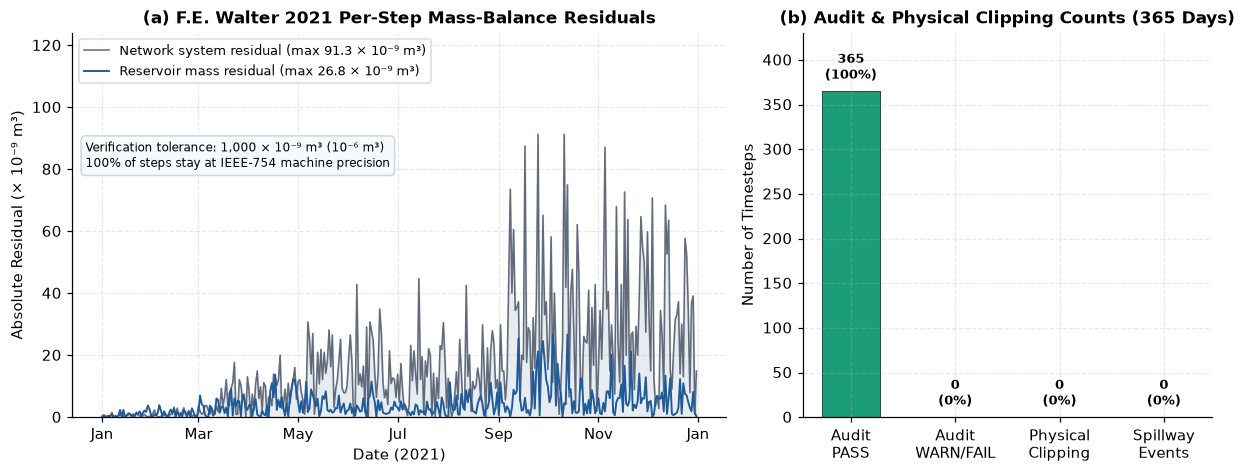

In [4]:
from collections import Counter
import matplotlib.dates as mdates
import numpy as np

traj_df["date_dt"] = pd.to_datetime(traj_df["date"].str.slice(0, 10))
reported_resid_m3 = traj_df["mass_balance_residual_m3"].abs().to_numpy(dtype=float)
# Independent per-step reservoir mass-balance residual (same check performed by verify_run)
recomputed_res_m3 = np.abs(
    (traj_df["storage_end_m3"].to_numpy(dtype=float) - traj_df["storage_start_m3"].to_numpy(dtype=float))
    - (traj_df["inflow_cms"].to_numpy(dtype=float) - traj_df["total_outflow_cms"].to_numpy(dtype=float)) * 86400.0
)
# Whole-network system balance residual from network_balance.csv
sys_col = next(c for c in balance_df.columns if "residual" in c.lower())
sys_resid_m3 = balance_df[sys_col].abs().to_numpy(dtype=float)

res_nm3 = recomputed_res_m3 * 1e9
sys_nm3 = sys_resid_m3 * 1e9

audit_counter = Counter(str(rec.get("status", "UNKNOWN")) for rec in audit_records)
pass_count = audit_counter.get("PASS", 0)
warn_fail_count = sum(v for k, v in audit_counter.items() if k != "PASS")
clipping_count = int(
    traj_df["adjustments"].fillna("").astype(str).str.strip().isin(["", "[]"]).eq(False).sum()
)
spill_count = int((traj_df["spill_cms"].astype(float) > 0.0).sum())

diag_summary = pd.DataFrame([
    {"Metric": "Daily steps verified", "Value": f"{len(traj_df)}"},
    {"Metric": "Max reported trajectory residual (m3)", "Value": f"{reported_resid_m3.max():.3e}"},
    {"Metric": "Max recomputed reservoir residual (m3)", "Value": f"{recomputed_res_m3.max():.3e}"},
    {"Metric": "Max network system residual (m3)", "Value": f"{sys_resid_m3.max():.3e}"},
    {"Metric": "Audit PASS / WARN+FAIL", "Value": f"{pass_count} / {warn_fail_count}"},
    {"Metric": "Physical clipping / Spill days", "Value": f"{clipping_count} / {spill_count}"},
])
print("=== Per-Step Mass-Balance & Audit Telemetry Summary (2021) ===")
print(diag_summary.to_string(index=False))

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(11.2, 4.4), gridspec_kw={"width_ratios": [1.6, 1.0]}
)

# Panel (a): Per-step independent reservoir & whole-network mass-balance residuals
ax1.fill_between(traj_df["date_dt"], 0.0, sys_nm3, color="#cbd5e0", alpha=0.45)
ax1.plot(traj_df["date_dt"], sys_nm3, color="#4a5568", lw=1.05, alpha=0.85,
         label=f"Network system residual (max {sys_nm3.max():.1f} × 10⁻⁹ m³)")
ax1.plot(traj_df["date_dt"], res_nm3, color="#1f5a99", lw=1.25,
         label=f"Reservoir mass residual (max {res_nm3.max():.1f} × 10⁻⁹ m³)")
ax1.set_title("(a) F.E. Walter 2021 Per-Step Mass-Balance Residuals")
ax1.set_ylabel("Absolute Residual (× 10⁻⁹ m³)")
ax1.set_xlabel("Date (2021)")
ax1.set_ylim(0, max(sys_nm3.max(), res_nm3.max()) * 1.36)
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax1.text(
    0.02, 0.72,
    "Verification tolerance: 1,000 × 10⁻⁹ m³ (10⁻⁶ m³)\n100% of steps stay at IEEE-754 machine precision",
    transform=ax1.transAxes,
    fontsize=8.1,
    va="top",
    bbox={"boxstyle": "round,pad=0.35", "facecolor": "#f7fafc", "edgecolor": "#cbd5e0"},
)
ax1.legend(loc="upper left", fontsize=8.3)

# Panel (b): Audit & physical constraint counts
categories = ["Audit\nPASS", "Audit\nWARN/FAIL", "Physical\nClipping", "Spillway\nEvents"]
counts = [pass_count, warn_fail_count, clipping_count, spill_count]
colors = ["#1b9e77", "#d95f02", "#7570b3", "#c0392b"]
bars = ax2.bar(categories, counts, color=colors, width=0.56, edgecolor="#2d3748", linewidth=0.6)
ax2.set_title("(b) Audit & Physical Clipping Counts (365 Days)")
ax2.set_ylabel("Number of Timesteps")
ax2.set_ylim(0, len(traj_df) * 1.18)
for bar, val in zip(bars, counts):
    pct = 100.0 * val / len(traj_df)
    ax2.text(
        bar.get_x() + bar.get_width() / 2.0,
        val + len(traj_df) * 0.025,
        f"{val}\n({pct:.0f}%)",
        ha="center",
        va="bottom",
        fontsize=8.6,
        fontweight="bold",
    )

fig.tight_layout()
plt.show()


## 4. Offline Replay — Exact SHA-256 Hash & Score Reproduction (`network_calls = 0`)

Even when an LLM model tag is updated upstream or a reviewer has no GPU/API key, HydroReOpLLM guarantees **bit-exact offline reproducibility** by archiving recorded LLM release series (`archived_releases.csv`) with a SHA-256 digest and replaying them through `RecordedResponseBackend` and the pinned HydroCNHS physics kernel.

Below we execute `examples/multi_reservoir/study/replay.py` inside a fresh `TemporaryDirectory()`, independently recompute the SHA-256 of `archived_releases.csv`, and confirm `status = PASS`, `network_calls = 0`, and exact reproduction of all 6 benchmark scores (`rule_based` and `hybrid_llm` across Feitsui level, Feitsui release, and downstream Xindian flow).


In [5]:
import importlib.util

mr_study = REPO_ROOT / "examples" / "multi_reservoir" / "study"
replay_script = mr_study / "replay.py"
archived_csv = mr_study / "archived_releases.csv"

spec = importlib.util.spec_from_file_location("xindian_study_replay", replay_script)
replay_module = importlib.util.module_from_spec(spec)
assert spec is not None and spec.loader is not None
spec.loader.exec_module(replay_module)

expected_archive_sha = hashlib.sha256(archived_csv.read_bytes()).hexdigest()

with tempfile.TemporaryDirectory(prefix="xindian-replay-m05-") as tmp:
    replay_out = Path(tmp) / "xindian-replay"
    replay_result = replay_module.replay(replay_out)
    scores_df = pd.read_csv(replay_out / "scores.csv")
    scores_sha256 = hashlib.sha256((replay_out / "scores.csv").read_bytes()).hexdigest()

assert replay_result["status"] == "PASS"
assert replay_result["network_calls"] == 0
assert replay_result["scores_verified"] == 6
assert replay_result["release_sha256"] == expected_archive_sha

print("=== Offline Xindian River Replay Result (examples/multi_reservoir/study/replay.py) ===")
print(f"  Status                 : {replay_result['status']}")
print(f"  Network calls          : {replay_result['network_calls']}")
print(f"  Runs / Scores verified : {replay_result['runs']} runs / {replay_result['scores_verified']} score triplets")
print(f"  archived_releases.csv  : sha256={replay_result['release_sha256']}")
print(f"  Exact hash match       : {replay_result['release_sha256'] == expected_archive_sha}")
print(f"  Exported scores.csv    : sha256={scores_sha256[:24]}...")

print("\n=== Reproduced 2025 Benchmark Scores (vs. TFRA Observations) ===")
display_cols = ["condition", "seed", "quantity", "pairs", "kge", "nse", "rmse"]
formatted = scores_df[display_cols].copy()
for col in ("kge", "nse", "rmse"):
    formatted[col] = formatted[col].map(lambda v: round(float(v), 4))
print(formatted.to_string(index=False))



=== Offline Xindian River Replay Result (examples/multi_reservoir/study/replay.py) ===
  Status                 : PASS
  Network calls          : 0
  Runs / Scores verified : 2 runs / 6 score triplets
  archived_releases.csv  : sha256=00ead833659fe662be0d73dd8705ae128b13a59d0f2d54290bfa658e595f1f27
  Exact hash match       : True
  Exported scores.csv    : sha256=b9df58fa1696d8ae875755fe...

=== Reproduced 2025 Benchmark Scores (vs. TFRA Observations) ===
 condition  seed        quantity  pairs    kge     nse    rmse
rule_based     0   Feitsui level    365 0.9151  0.3578  3.6344
rule_based     0 Feitsui release    365 0.4469  0.0998 37.6263
rule_based     0 Downstream flow    365 0.7596  0.5684 57.4809
hybrid_llm     3   Feitsui level    365 0.6011  0.4980  3.2135
hybrid_llm     3 Feitsui release    365 0.4596 -0.2504 44.3463
hybrid_llm     3 Downstream flow    365 0.6905  0.5618 57.9189


## Key Takeaways & Curriculum Summary

- **Automatic ODD+LLM persistence:** Every HydroReOpLLM run writes `odd_llm_manifest.json` (`odd-llm-reproducibility.v1`) and pins its SHA-256 inside `summary.json`, so any tampering is immediately flagged by `verify_run`.
- **One-command publication reporting:** Use `export_odd_report(..., json_out=..., markdown_out=...)` in Python — or `reservoir-experiment export-odd <run_dir> --markdown-out odd_report.md` on the CLI — to generate standardized Blocks `A`–`E` tables for manuscript supplements.
- **Physical + cryptographic assurance:** Combining per-step mass-balance residuals (`~10⁻⁸ m³`), audit/clipping telemetry (`audit.jsonl`), and zero-network `replay.py` verification guarantees reproducible, peer-auditable LLM-coupled hydrological modeling.
- **Completed the 5-Module Curriculum!** Return to [`tutorials/README.md`](../README.md) or explore the shipped protocol cards ([`examples/fe_walter/ODD_LLM.md`](../../examples/fe_walter/ODD_LLM.md) and [`examples/multi_reservoir/ODD_LLM.md`](../../examples/multi_reservoir/ODD_LLM.md)).
